In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [4]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [5]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [6]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [9]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [10]:
def getRcsData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [11]:
def getRcsErrData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    p = n_ss/(n_ss+n_os)
    return 2*np.sqrt(p*(1-p)/(n_ss+n_os))

In [12]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [96]:
def getRcsArr(bins, df, ob):
    rcs_arr = []
    rcs_err_arr = []
    for i in range(0,len(bins)-1):
        rcs_arr.append(getRcs(applyCut(df,str(bins[i])+'<'+str(ob)+'<'+str(bins[i+1]))))
        rcs_err_arr.append(getRcsErr(applyCut(df,str(bins[i])+'<'+str(ob)+'<'+str(bins[i+1]))))
    return rcs_arr, rcs_err_arr

In [97]:
def getRcsDataArr(bins, df, ob):
    rcs_arr = []
    rcs_err_arr = []
    for i in range(0,len(bins)-1):
        rcs_arr.append(getRcsData(applyCut(df,str(bins[i])+'<'+str(ob)+'<'+str(bins[i+1]))))
        rcs_err_arr.append(getRcsErrData(applyCut(df,str(bins[i])+'<'+str(ob)+'<'+str(bins[i+1]))))
    return rcs_arr, rcs_err_arr

In [13]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [14]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2','reject','w']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s','rejects','ws']

In [15]:
df_geant = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all0613_chargedrc.root', "MatchedTree"),'bs!=-9 and 10<pts<30 and reject<=0 and rejects<=0')

In [30]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2', 'q0', 'q2']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s', 'q0s', 'q2s']
df_data = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0613_chargedrc.root', "ResultTree"),'10<pts<30 and bs!=-9')

In [55]:
df_geant.eval('pt1sfrac=pt1s/pts',inplace=True)
df_data.eval('pt1sfrac=pt1s/pts',inplace=True)

(array([3.38772676e-06, 3.24738561e-05, 5.08879060e-05, 3.87938354e-05,
        1.99571793e-05, 1.11771804e-05, 5.63871839e-06, 2.28173515e-06,
        8.76046762e-07, 2.37282343e-07]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

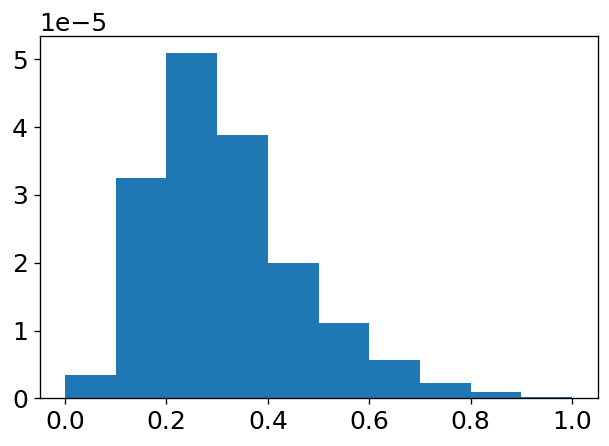

In [58]:
plt.hist(df_geant['pt1sfrac'], weights=df_geant['ws'], range=(0,1))

(array([2.88922169e-05, 2.94454284e-05, 2.47038917e-05, 2.18709200e-05,
        1.77708737e-05, 1.34944465e-05, 1.10317844e-05, 8.48237844e-06,
        6.00704158e-06, 1.00739124e-06]),
 array([0.5 , 0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 10 artists>)

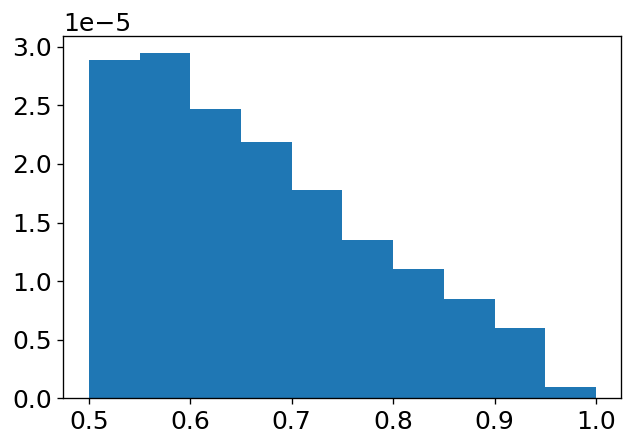

In [45]:
plt.hist(df_geant['zs'], weights=df_geant['ws'], range=(0.5,1))

In [66]:
bins=np.arange(0,1.2,0.2)
bincenter=np.arange(0.1,1.1,0.2)

In [67]:
rcs_arr, rcs_err_arr = getRcsArr(bins, df_geant, 'pt1sfrac')

In [68]:
rcs_arr_data, rcs_err_arr_data = getRcsDataArr(bins, df_data, 'pt1sfrac')

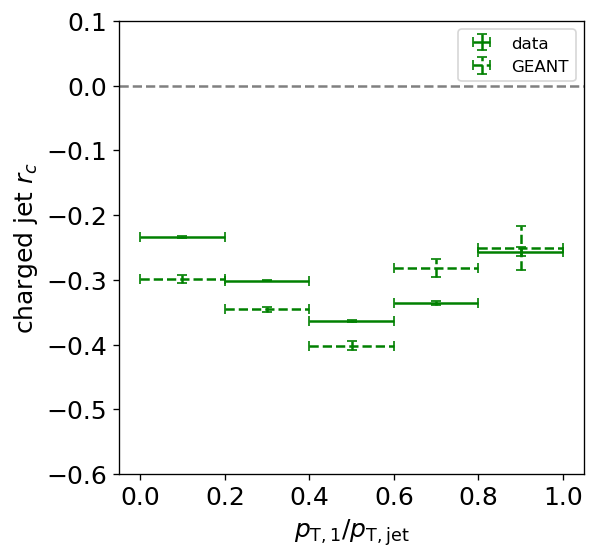

In [69]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs_arr_data, xerr=[0.1]*5, yerr=rcs_err_arr_data, capsize=3, color='g', ls='none', label='data')
eb1=plt.errorbar(bincenter, rcs_arr, xerr=[0.1]*5, yerr=rcs_err_arr, capsize=3, color='g', ls='none', label='GEANT')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('$p_{\mathrm{T,1}}/p_{\mathrm{T,jet}}$', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [70]:
bins=np.arange(0.5,1.05,0.05)
bincenter=np.arange(0.525,1.025,0.05)

In [71]:
rcs_arr, rcs_err_arr = getRcsArr(bins, df_geant, 'zs')

In [72]:
rcs_arr_data, rcs_err_arr_data = getRcsDataArr(bins, df_data, 'zs')

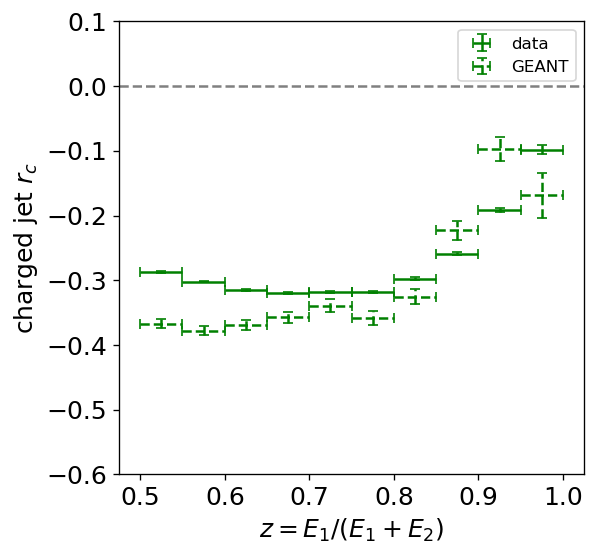

In [74]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs_arr_data, xerr=[0.025]*10, yerr=rcs_err_arr_data, capsize=3, color='g', ls='none', label='data')
eb1=plt.errorbar(bincenter, rcs_arr, xerr=[0.025]*10, yerr=rcs_err_arr, capsize=3, color='g', ls='none', label='GEANT')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('$z=E_1/(E_1+E_2)$', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [98]:
bins=np.arange(0,22,2)
bincenter=np.arange(1,21,2)

In [99]:
rcs_arr, rcs_err_arr = getRcsArr(bins, df_geant, 'pt1s')

In [100]:
rcs_arr_data, rcs_err_arr_data = getRcsDataArr(bins, df_data, 'pt1s')

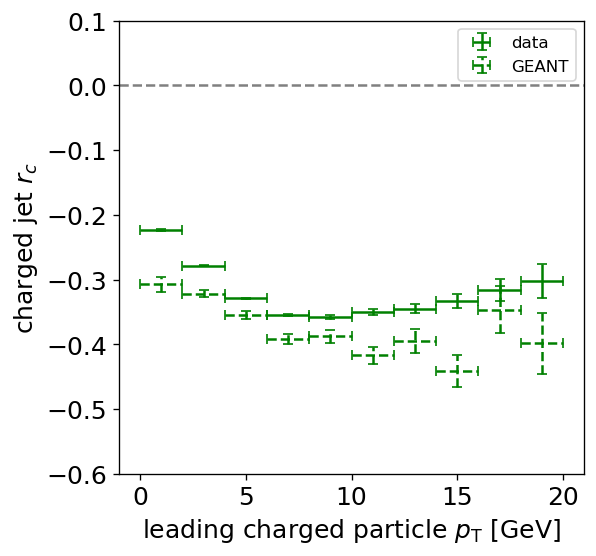

In [102]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs_arr_data, xerr=[1]*10, yerr=rcs_err_arr_data, capsize=3, color='g', ls='none', label='data')
eb1=plt.errorbar(bincenter, rcs_arr, xerr=[1]*10, yerr=rcs_err_arr, capsize=3, color='g', ls='none', label='GEANT')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('leading charged particle $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)
#plt.xlim(0,20)